<a href="https://colab.research.google.com/github/yahyarigati/simcosta-wave-height-forecasting/blob/main/RJ4_Wave_Height_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecasting wave height from the SiMCosta RJ-4 buoy

Can the past 24 hours of significant wave height (`Hsig`) improve a forecast of the next hourly average? A second experiment asks how soon a shorter model can resume forecasts after an observation gap.


In [1]:
from google.colab import files

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("Select one RJ-4 oceanographic CSV export.")
filename = next(iter(uploaded))
print(filename)

Saving SIMCOSTA_RJ-4_OCEAN_2017-08-27_2026-11-24.csv to SIMCOSTA_RJ-4_OCEAN_2017-08-27_2026-11-24.csv
SIMCOSTA_RJ-4_OCEAN_2017-08-27_2026-11-24.csv


In [2]:
import csv
from itertools import islice

import pandas as pd

with open(filename, encoding="utf-8-sig") as file:
    first_lines = list(islice(file, 100))

header_matches = []
for line_number, line in enumerate(first_lines):
    for separator in [",", ";", "\t"]:
        fields = next(csv.reader([line], delimiter=separator), [])
        if len(fields) > 1 and any(field.strip().lower() == "hsig" for field in fields):
            header_matches.append((line_number, separator))

if not header_matches:
    raise ValueError("Could not find an Hsig header in the first 100 lines.")

header_row, separator = header_matches[0]
df = pd.read_csv(filename, skiprows=header_row, sep=separator, na_values=["NULL"])
df.columns = df.columns.str.strip()
print("Rows and columns:", df.shape)

Rows and columns: (125341, 28)


In [3]:
import numpy as np
import pandas as pd

time_columns = ["YEAR", "MONTH", "DAY", "HOUR", "MINUTE", "SECOND"]

timestamps = pd.to_datetime(
    df[time_columns].rename(columns=str.lower),
    errors="coerce",
)
wave_height = pd.to_numeric(df["Hsig"], errors="coerce")
wave_height = wave_height.replace([np.inf, -np.inf], np.nan)

readings = pd.DataFrame({"time": timestamps, "Hsig": wave_height})

print("Invalid timestamps:", readings["time"].isna().sum())
print("Missing or non-numeric Hsig:", readings["Hsig"].isna().sum())

readings = readings.dropna(subset=["time"]).sort_values("time")
print("Extra rows with a repeated timestamp:", readings["time"].duplicated().sum())

# Give each distinct timestamp equal weight in its hourly average.
by_timestamp = readings.groupby("time")["Hsig"].mean()
hourly = by_timestamp.resample("1h").mean()

print("Time range:", hourly.index.min(), "to", hourly.index.max())
print("Hours with an Hsig average:", hourly.notna().sum())
print("Hours without an Hsig average:", hourly.isna().sum())

Invalid timestamps: 0
Missing or non-numeric Hsig: 8156
Extra rows with a repeated timestamp: 0
Time range: 2017-08-28 13:00:00 to 2026-11-24 13:00:00
Hours with an Hsig average: 67221
Hours without an Hsig average: 13780


## Build sequences and split by target time
A usable example contains 24 consecutive input hours and one observed target hour. Split the calendar timeline in chronological order (70% training, 15% validation, 15% test). Persistence forecasts the last input value.

In [4]:
lookback = 24

# Each window contains 24 input hours and 1 target hour.
valid_hours = hourly.notna().astype(int)
complete_windows = valid_hours.rolling(lookback + 1).sum().eq(lookback + 1)

possible_windows = max(len(hourly) - lookback, 0)
usable_windows = int(complete_windows.sum())

print("Possible forecast windows:", possible_windows)
print("Usable forecast windows:", usable_windows)

if possible_windows:
    print(f"Usable share: {usable_windows / possible_windows:.1%}")

Possible forecast windows: 80977
Usable forecast windows: 43670
Usable share: 53.9%


In [5]:
from numpy.lib.stride_tricks import sliding_window_view

values = hourly.to_numpy(dtype=np.float32)

# Each row has 24 input hours followed by 1 target hour.
windows = sliding_window_view(values, window_shape=lookback + 1)
usable = complete_windows.iloc[lookback:].to_numpy()
target_times = hourly.index[lookback:][usable]

X = windows[usable, :lookback][..., np.newaxis]
y = windows[usable, lookback]

# Choose split dates from the full hourly timeline.
validation_start = hourly.index[int(0.70 * len(hourly))]
test_start = hourly.index[int(0.85 * len(hourly))]

train_mask = target_times < validation_start
val_mask = (target_times >= validation_start) & (target_times < test_start)
test_mask = target_times >= test_start

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Validation starts:", validation_start)
print("Test starts:", test_start)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Validation starts: 2024-02-16 01:00:00
Test starts: 2025-07-06 07:00:00
Training shape: (26362, 24, 1)
Validation shape: (10877, 24, 1)
Test shape: (6431, 24, 1)


## Explore availability and persistence
Monthly coverage uses hours within the export's time span, including partial boundary months. The second figure uses consecutive training observations. Vertical distance from the diagonal is the absolute error of a persistence forecast.

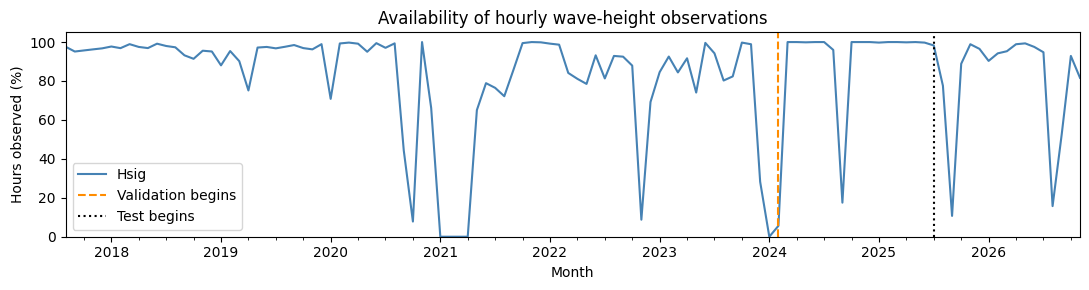

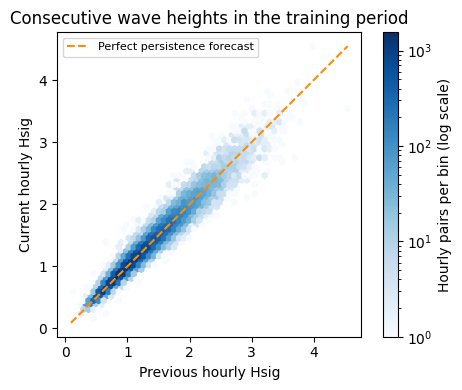

In [6]:
import matplotlib.pyplot as plt

monthly_coverage = hourly.notna().resample("MS").mean() * 100
ax = monthly_coverage.plot(figsize=(11, 3), color="steelblue")
ax.axvline(validation_start, color="darkorange", linestyle="--", label="Validation begins")
ax.axvline(test_start, color="black", linestyle=":", label="Test begins")
ax.set(title="Availability of hourly wave-height observations", ylabel="Hours observed (%)",
       xlabel="Month", ylim=(0, 105))
ax.legend()
plt.tight_layout()
plt.show()

training_series = hourly.loc[hourly.index < validation_start]
pairs = pd.concat([training_series.shift(1), training_series], axis=1).dropna()
pairs.columns = ["Previous hour", "Current hour"]
fig, ax = plt.subplots(figsize=(5, 4))
density = ax.hexbin(pairs["Previous hour"], pairs["Current hour"], gridsize=55,
                    bins="log", mincnt=1, cmap="Blues")
limits = [pairs.min().min(), pairs.max().max()]
ax.plot(limits, limits, "--", color="darkorange", label="Perfect persistence forecast")
ax.set(xlabel="Previous hourly Hsig", ylabel="Current hourly Hsig",
       title="Consecutive wave heights in the training period", aspect="equal")
ax.legend(fontsize=8)
fig.colorbar(density, ax=ax, label="Hourly pairs per bin (log scale)")
fig.tight_layout()
plt.show()

## Train the recurrent models
Both networks read one feature per hour and predict one hourly average. Scaling uses training observations only. Each model trains for ten epochs and retains the weights with the lowest validation MAE.

In [7]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Learn the scale from hourly observations in the training period only.
training_hours = hourly.loc[hourly.index < validation_start].dropna()
mean_hsig = float(training_hours.mean())
std_hsig = float(training_hours.std())

def scale_hsig(values):
    return torch.as_tensor((values - mean_hsig) / std_hsig, dtype=torch.float32)

train_data = TensorDataset(scale_hsig(X_train), scale_hsig(y_train))
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)

X_val_tensor = scale_hsig(X_val).to(device)
y_val_tensor = torch.as_tensor(y_val, dtype=torch.float32, device=device)

### Vanilla RNN

In [8]:
class WaveRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.output = nn.Linear(16, 1)

    def forward(self, x):
        _, final_hidden = self.rnn(x)
        prediction = self.output(final_hidden[-1])
        return prediction.squeeze(-1)

model = WaveRNN().to(device)

In [9]:
from copy import deepcopy

loss_fn = nn.L1Loss()  # Mean absolute error
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

persistence_mae = float(np.mean(np.abs(X_val[:, -1, 0] - y_val)))
best_val_mae = float("inf")

for epoch in range(1, 11):
    model.train()

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        predictions = model(inputs)
        loss = loss_fn(predictions, targets)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        # Return predictions to the original Hsig units before scoring.
        val_predictions = model(X_val_tensor) * std_hsig + mean_hsig
        rnn_mae = loss_fn(val_predictions, y_val_tensor).item()

    if rnn_mae < best_val_mae:
        best_val_mae = rnn_mae
        best_weights = deepcopy(model.state_dict())


_ = model.load_state_dict(best_weights)

### LSTM

In [10]:
class WaveLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
        self.output = nn.Linear(16, 1)

    def forward(self, x):
        _, (hidden, cell) = self.lstm(x)
        return self.output(hidden[-1]).squeeze(-1)

torch.manual_seed(42)
lstm_model = WaveLSTM().to(device)

In [11]:
lstm_optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
best_lstm_mae = float("inf")

for epoch in range(1, 11):
    lstm_model.train()

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        lstm_optimizer.zero_grad()
        predictions = lstm_model(inputs)
        loss = loss_fn(predictions, targets)
        loss.backward()
        lstm_optimizer.step()

    lstm_model.eval()
    with torch.no_grad():
        val_predictions = lstm_model(X_val_tensor) * std_hsig + mean_hsig
        epoch_mae = loss_fn(val_predictions, y_val_tensor).item()

    if epoch_mae < best_lstm_mae:
        best_lstm_mae = epoch_mae
        best_lstm_epoch = epoch
        best_lstm_weights = deepcopy(lstm_model.state_dict())


_ = lstm_model.load_state_dict(best_lstm_weights)

## Compare models on validation targets
Ridge regression learns one coefficient per hourly lag. Compare it with persistence and both recurrent networks on the same hours.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Ridge expects one row per example and one column per hourly reading.
# Shape changes from (examples, 24, 1) to (examples, 24).
X_train_ridge = X_train[:, :, 0]
X_val_ridge = X_val[:, :, 0]

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train_ridge, y_train)

ridge_val_predictions = ridge.predict(X_val_ridge)
ridge_val_mae = mean_absolute_error(y_val, ridge_val_predictions)

validation_results = pd.Series({
    "Persistence": persistence_mae,
    "Ridge (24 hours)": ridge_val_mae,
    "Vanilla RNN": best_val_mae,
    "LSTM": best_lstm_mae,
}, name="Validation MAE")

display(validation_results.sort_values().round(5))

,Validation MAE
LSTM,0.05958
Ridge (24 hours),0.05990
Vanilla RNN,0.06040
Persistence,0.06181


## Test extra features and shorter histories
Check whether peak period (`TP`) and maximum wave height (`Hmax`) were available when the forecast would have been issued. The additional Ridge feature is the previous hour's mean of reported maxima.

In [13]:
coverage_rows = []

for feature in ["TP", "Hmax"]:
    readings = pd.DataFrame({
        "time": timestamps,
        "value": pd.to_numeric(df[feature], errors="coerce"),
    })
    readings["value"] = readings["value"].replace([np.inf, -np.inf], np.nan)

    # Use the same hourly averaging convention as the Hsig experiment.
    hourly_feature = (
        readings.dropna(subset=["time"])
        .groupby("time")["value"].mean()
        .resample("1h").mean()
        .reindex(hourly.index)
    )

    # For target hour t, the latest available input hour is t-1.
    previous_hour = hourly_feature.shift(1)
    full_history = previous_hour.notna().rolling(lookback).sum().eq(lookback)

    for split, mask in [("Training", train_mask), ("Validation", val_mask)]:
        times = target_times[mask]
        latest_count = int(previous_hour.loc[times].notna().sum())
        coverage_rows.append({
            "Feature": feature,
            "Split": split,
            "Hsig examples": len(times),
            "With previous hour": latest_count,
            "Previous-hour coverage (%)": round(100 * latest_count / len(times), 1),
            "With all 24 hours": int(full_history.loc[times].sum()),
        })

display(pd.DataFrame(coverage_rows).set_index(["Feature", "Split"]))

Hsig examples  With previous hour  \
Feature Split                                           
TP      Training            26362                   0   
        Validation          10877                   0   
Hmax    Training            26362               26362   
        Validation          10877               10877   

                    Previous-hour coverage (%)  With all 24 hours  
Feature Split                                                      
TP      Training                           0.0                  0  
        Validation                         0.0                  0  
Hmax    Training                         100.0              26362  
        Validation                       100.0              10877

In [14]:
# Build the hourly Hmax feature explicitly so the cell is reproducible.
hmax = pd.to_numeric(df["Hmax"], errors="coerce").replace([np.inf, -np.inf], np.nan)
hourly_hmax = (
    pd.DataFrame({"time": timestamps, "Hmax": hmax})
    .dropna(subset=["time"])
    .groupby("time")["Hmax"].mean()
    .resample("1h").mean()
    .reindex(hourly.index)
)

# At target hour t, use Hmax from the completed hour t-1.
previous_hmax = hourly_hmax.shift(1)
train_hmax = previous_hmax.loc[target_times[train_mask]].to_numpy()
val_hmax = previous_hmax.loc[target_times[val_mask]].to_numpy()

# Verify the 100% coverage before comparing the models.
assert np.isfinite(train_hmax).all() and np.isfinite(val_hmax).all()

X_train_plus_hmax = np.column_stack([X_train_ridge, train_hmax])
X_val_plus_hmax = np.column_stack([X_val_ridge, val_hmax])

ridge_hmax = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_hmax.fit(X_train_plus_hmax, y_train)
ridge_hmax_mae = mean_absolute_error(y_val, ridge_hmax.predict(X_val_plus_hmax))

gain_pct = 100 * (ridge_val_mae - ridge_hmax_mae) / ridge_val_mae
print(f"Ridge with 24 Hsig inputs:       {ridge_val_mae:.6f}")
print(f"Ridge with 24 Hsig + last Hmax:  {ridge_hmax_mae:.6f}")
print(f"MAE reduction from adding Hmax:  {gain_pct:+.2f}%")

Ridge with 24 Hsig inputs:       0.059896
Ridge with 24 Hsig + last Hmax:  0.059902
MAE reduction from adding Hmax:  -0.01%


### Accuracy on shared hours and coverage after gaps
Compare input lengths on identical targets first. Then score six-hour Ridge on the additional validation hours where 24-hour models could not issue a forecast.

In [15]:
lookback_results = []

for hours in [1, 6, 12, 24]:
    # Columns run from oldest to newest. Keep the most recent hours.
    train_inputs = X_train_ridge[:, -hours:]
    val_inputs = X_val_ridge[:, -hours:]

    model_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model_ridge.fit(train_inputs, y_train)
    predictions = model_ridge.predict(val_inputs)
    mae = mean_absolute_error(y_val, predictions)

    lookback_results.append({
        "History (hours)": hours,
        "Validation MAE": mae,
        "MAE reduction vs persistence (%)":
            100 * (persistence_mae - mae) / persistence_mae,
    })

display(pd.DataFrame(lookback_results).set_index("History (hours)").round(6))

,Validation MAE,MAE reduction vs persistence (%)
History (hours),,
1,0.061818,-0.018516
6,0.059980,2.955885
12,0.059926,3.043149
24,0.059896,3.091603


In [16]:
# Fit the same six-hour Ridge model used in the lookback experiment.
ridge_6h = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_6h.fit(X_train_ridge[:, -6:], y_train)

# Each row represents a target hour. Its columns contain earlier observations.
lags = pd.DataFrame({
    f"lag_{h}": hourly.shift(h) for h in range(24, 0, -1)
})
six_hour_columns = [f"lag_{h}" for h in range(6, 0, -1)]

in_validation = (hourly.index >= validation_start) & (hourly.index < test_start)
has_6h = lags[six_hour_columns].notna().all(axis=1)
has_24h = lags.notna().all(axis=1)

# These forecasts could be issued even if the target later went unobserved.
extra_hours = in_validation & has_6h & ~has_24h
# Only observed targets can be used to calculate forecast error.
scorable = extra_hours & hourly.notna()

print("Extra validation hours forecastable:", int(extra_hours.sum()))
print("Extra hours with an observed target:", int(scorable.sum()))

if scorable.any():
    actual = hourly.loc[scorable]
    ridge_forecast = ridge_6h.predict(lags.loc[scorable, six_hour_columns].to_numpy())
    persistence_forecast = lags.loc[scorable, "lag_1"]

    print(f"Six-hour Ridge MAE: {mean_absolute_error(actual, ridge_forecast):.6f}")
    print(f"Persistence MAE:    {mean_absolute_error(actual, persistence_forecast):.6f}")

Extra validation hours forecastable: 250
Extra hours with an observed target: 246
Six-hour Ridge MAE: 0.076471
Persistence MAE:    0.078516


## Held-out results for the original forecasting experiment
Evaluate the selected RNN and LSTM against persistence on the same test targets. The figure shows the first seven calendar days.

In [17]:
# Apply the scaling learned from the training period.
X_test_tensor = scale_hsig(X_test).to(device)

model.eval()       # Trained vanilla RNN
lstm_model.eval()  # Trained LSTM

with torch.no_grad():
    # Convert neural network forecasts back to the original Hsig units.
    rnn_test = (model(X_test_tensor) * std_hsig + mean_hsig).cpu().numpy()
    lstm_test = (lstm_model(X_test_tensor) * std_hsig + mean_hsig).cpu().numpy()

# X_test is already in the original units.
persistence_test = X_test[:, -1, 0]

forecasts = pd.DataFrame(
    {
        "Observed": y_test,
        "Persistence": persistence_test,
        "RNN": rnn_test,
        "LSTM": lstm_test,
    },
    index=target_times[test_mask],
)
forecasts.index.name = "Target hour"

errors = forecasts[["Persistence", "RNN", "LSTM"]].sub(
    forecasts["Observed"], axis="index"
)
test_mae = errors.abs().mean()

results = pd.DataFrame({
    "Test MAE": test_mae,
    "MAE reduction vs persistence (%)":
        100 * (1 - test_mae / test_mae["Persistence"]),
})

print("First test target:", forecasts.index.min())
print("Last test target:", forecasts.index.max())
print("Evaluated hours:", len(forecasts))
display(results.round(5))

First test target: 2025-07-06 07:00:00
Last test target: 2026-11-24 13:00:00
Evaluated hours: 6431


,Test MAE,MAE reduction vs persistence (%)
Persistence,0.06057,0.00000
RNN,0.05920,2.26194
LSTM,0.05819,3.92802


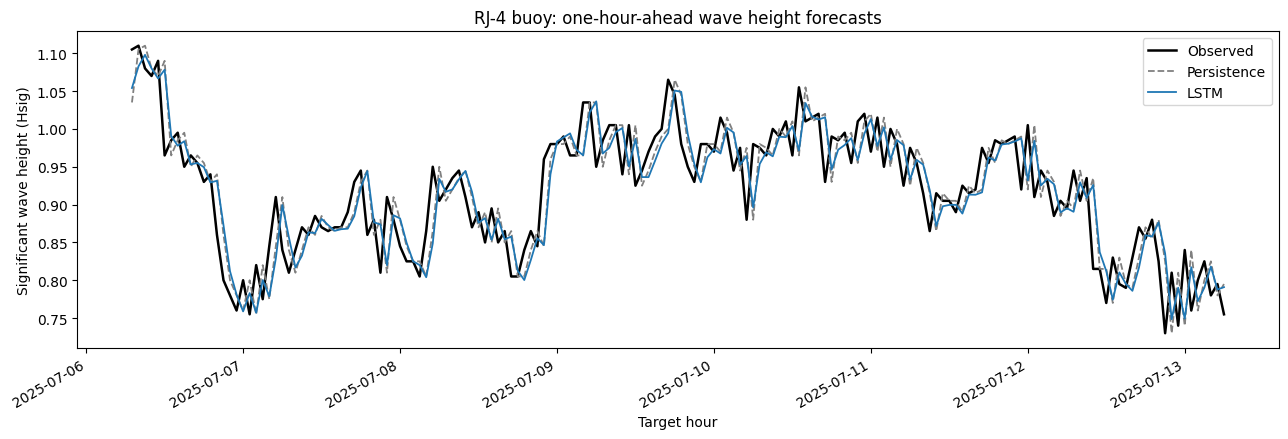

In [18]:
import matplotlib.pyplot as plt

start = forecasts.index.min()
week_index = pd.date_range(start=start, periods=7 * 24, freq="h")
week = forecasts.reindex(week_index)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(week.index, week["Observed"], color="black",
        linewidth=1.8, label="Observed")
ax.plot(week.index, week["Persistence"], color="gray",
        linestyle="--", linewidth=1.3, label="Persistence")
ax.plot(week.index, week["LSTM"], color="tab:blue",
        linewidth=1.3, label="LSTM")

ax.set_title("RJ-4 buoy: one-hour-ahead wave height forecasts")
ax.set_xlabel("Target hour")
ax.set_ylabel("Significant wave height (Hsig)")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [19]:
persistence_error = (forecasts["Observed"] - forecasts["Persistence"]).abs()
lstm_error = (forecasts["Observed"] - forecasts["LSTM"]).abs()

# Positive gain means the LSTM was closer to the observation.
gain = persistence_error - lstm_error

print(f"Hours when LSTM was closer: {(gain > 0).mean():.1%}")
print(f"Mean error reduction per hour: {gain.mean():.5f}")

Hours when LSTM was closer: 54.4%
Mean error reduction per hour: 0.00238


## Findings and limits

The LSTM reduced test MAE by **3.93%** versus persistence across **6,431 hours**. Adding the previous hour’s mean reported maximum wave height did little for Ridge on validation.

Six-hour Ridge could issue **250 additional validation forecasts** after gaps. On the 246 with observed targets, it reduced MAE by **2.60%** versus persistence.

Results cover one buoy and a one-hour horizon. Hourly averages may rely on a single reading, and forecasts assume the preceding hour’s readings arrive on time.